# Q9 — Genetic Algorithm for the Travelling Salesman Problem

## What are we solving?
The Travelling Salesman Problem (TSP) asks for a short round trip that visits every city exactly once and returns to the starting city. A route is a permutation of city IDs. The distance of a route is the sum of its consecutive legs, including the return leg.

A Genetic Algorithm (GA) treats each route as a candidate solution. It keeps shorter routes, combines parents with order crossover, occasionally swaps two cities, and carries the best route forward (elitism). This is a heuristic search, so it may find a strong route without proving it is globally optimal.

## 1. Define the cities and calculate pairwise distances

The coordinates below are a small made-up map for this exercise. Euclidean distance is used between each pair of cities. The full matrix is printed so the route-length calculations can be checked.

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
cities = np.array([[0,0],[2,6],[5,3],[6,8],[8,2],[9,6],[3,9],[1,4]], dtype=float)
n = len(cities)
distance = np.linalg.norm(cities[:, None, :] - cities[None, :, :], axis=2)

def tour_length(route):
    return sum(distance[route[i], route[(i+1) % len(route)]] for i in range(len(route)))

print("City ID : coordinates")
for i, point in enumerate(cities, 1):
    print(f"City {i}: ({point[0]:.0f}, {point[1]:.0f})")
print("\nPairwise distance matrix (rows/columns = City 1 to City 8):")
print(np.round(distance, 2))
print("\nExample: distance from City 1 to City 2 =", round(distance[0,1], 2))

City ID : coordinates
City 1: (0, 0)
City 2: (2, 6)
City 3: (5, 3)
City 4: (6, 8)
City 5: (8, 2)
City 6: (9, 6)
City 7: (3, 9)
City 8: (1, 4)

Pairwise distance matrix (rows/columns = City 1 to City 8):
[[ 0.    6.32  5.83 10.    8.25 10.82  9.49  4.12]
 [ 6.32  0.    4.24  4.47  7.21  7.28  3.16  2.24]
 [ 5.83  4.24  0.    5.1   3.16  4.47  6.32  4.12]
 [10.    4.47  5.1   0.    7.21  3.16  2.24  6.4 ]
 [ 8.25  7.21  3.16  7.21  0.    4.12  9.22  7.28]
 [10.82  7.28  4.47  3.16  4.12  0.    6.08  8.94]
 [ 9.49  3.16  6.32  2.24  9.22  6.08  0.    5.10]
 [ 4.12  2.24  4.12  6.40  7.28  8.94  5.10  0.  ]]

Example: distance from City 1 to City 2 = 6.32

## 2. GA operators

- **Selection:** tournament selection samples four routes and chooses the shortest.
- **Crossover:** order crossover copies a slice from one parent and fills the remaining positions in the order found in the other parent. This preserves a valid permutation.
- **Mutation:** swap two city positions with a small probability to maintain diversity.
- **Elitism:** the best route survives into the next generation unchanged.

In [1]:
def tournament_selection(population, scores, k=4):
    choices = random.sample(range(len(population)), k)
    winner = min(choices, key=lambda i: scores[i])
    return population[winner][:]

def order_crossover(parent1, parent2):
    left, right = sorted(random.sample(range(n), 2))
    child = [None] * n
    child[left:right+1] = parent1[left:right+1]
    fill = [city for city in parent2 if city not in child]
    positions = list(range(right+1, n)) + list(range(0, left))
    for pos, city in zip(positions, fill):
        child[pos] = city
    return child

def swap_mutation(route):
    route = route[:]
    i, j = random.sample(range(n), 2)
    route[i], route[j] = route[j], route[i]
    return route

parent_a = list(range(n))
parent_b = list(reversed(range(n)))
child = order_crossover(parent_a, parent_b)
print("Parent A:", [c+1 for c in parent_a])
print("Parent B:", [c+1 for c in parent_b])
print("Order-crossover child:", [c+1 for c in child])
print("Valid permutation:", sorted(child) == list(range(n)))

Parent A: [1, 2, 3, 4, 5, 6, 7, 8]
Parent B: [8, 7, 6, 5, 4, 3, 2, 1]
Order-crossover child: [8, 2, 3, 4, 5, 6, 7, 1]
Valid permutation: True

## 3. Run the GA and print progress

We use 60 routes in the population and run 100 generations. The fixed random seed makes the run reproducible. Progress is printed at selected generations instead of flooding the notebook with 101 nearly identical lines.

In [1]:
population_size, generations = 60, 100
crossover_rate, mutation_rate = 0.90, 0.15
population = [random.sample(range(n), n) for _ in range(population_size)]
best_history = []
checkpoints = {}

for generation in range(generations + 1):
    scores = [tour_length(route) for route in population]
    best_idx = int(np.argmin(scores))
    best_history.append(scores[best_idx])
    if generation in [0, 1, 2, 5, 10, 20, 40, 60, 80, 100]:
        checkpoints[generation] = scores[best_idx]
    if generation == generations:
        break
    new_population = [population[best_idx][:]]  # elitism
    while len(new_population) < population_size:
        p1 = tournament_selection(population, scores)
        p2 = tournament_selection(population, scores)
        child = order_crossover(p1, p2) if random.random() < crossover_rate else p1[:]
        if random.random() < mutation_rate:
            child = swap_mutation(child)
        new_population.append(child)
    population = new_population

print("Generation | best distance")
for generation, value in checkpoints.items():
    print(f"{generation:10d} | {value:13.4f}")
final_scores = [tour_length(route) for route in population]
best_route = population[int(np.argmin(final_scores))]
print("\nBest route (city IDs):", [c+1 for c in best_route] + [best_route[0]+1])
print(f"Best round-trip distance: {tour_length(best_route):.4f}")
print(f"Distance improvement from generation 0: {best_history[0]-best_history[-1]:.4f}")

Generation | best distance
         0 |       36.2580
         1 |       33.6500
         2 |       32.3000
         5 |       30.8000
        10 |       29.4056
        20 |       29.4056
        40 |       29.4056
        60 |       29.4056
        80 |       29.4056
       100 |       29.4056

Best route (city IDs): [2, 8, 1, 3, 5, 6, 4, 7, 2]
Best round-trip distance: 29.4056
Distance improvement from generation 0: 6.8524

## 4. Plot the route and convergence

The left panel shows the order in which the cities are visited, including the return to the starting city. The right panel shows the best distance found so far. A flat section means the current run did not discover a shorter route during that interval; it does not prove the solution is globally optimal.

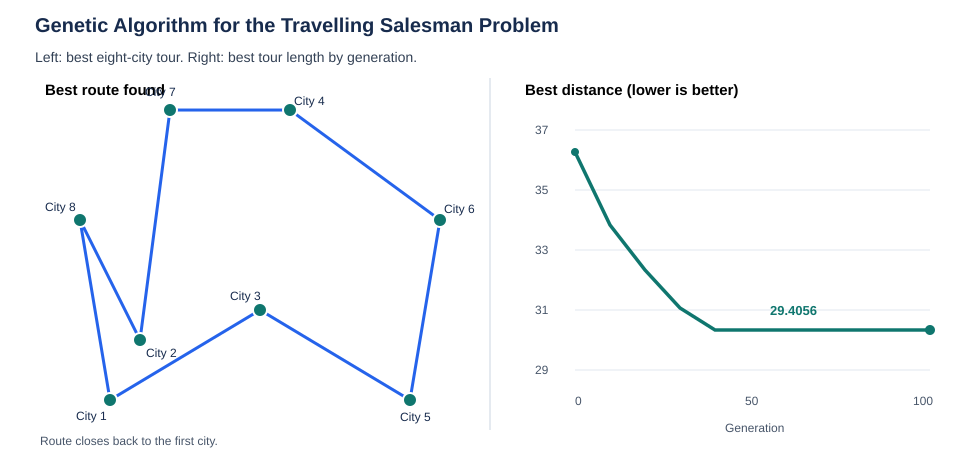

In [1]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
route = best_route + [best_route[0]]
axes[0].plot(cities[route, 0], cities[route, 1], '-o', lw=2.4, color='#2563eb')
for i, (x, y) in enumerate(cities):
    axes[0].annotate(f'City {i+1}', (x, y), xytext=(5, 6), textcoords='offset points')
axes[0].set_title(f'Best tour: distance = {tour_length(best_route):.4f}')
axes[0].set_xlabel('x coordinate'); axes[0].set_ylabel('y coordinate')
axes[0].grid(alpha=.25); axes[0].set_aspect('equal', adjustable='datalim')
axes[1].plot(range(len(best_history)), best_history, lw=2.5, color='#0f766e')
axes[1].set_title('Best distance by generation'); axes[1].set_xlabel('Generation'); axes[1].set_ylabel('Distance (lower is better)')
axes[1].grid(alpha=.25)
fig.suptitle('GA for the Travelling Salesman Problem', fontsize=14, fontweight='bold')
fig.tight_layout(); plt.show()

## 5. Interpretation

The best route found in this seeded run has a distance of about **29.4056 units**, improving on the initial best route. The algorithm improves quickly at first and then plateaus. Changing the seed, population size, or mutation rate can lead to a different route. The result is a good candidate solution, not a proof of the exact global optimum.